# 03 — Signatures · Wang et al. 2019 (Glioblastoma)

Score the three embryonic modules (Gast, pSom, Crest) with the `union` control pool and render each as a **raw** per-cell signature UMAP (smoothing aids reading in 02 but misleads as a deliverable), with external colorbars. Gate 2 is judged from the module geography shown here.

In [1]:
import os, glob
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
category = os.path.split(os.path.split(os.getcwd())[0])[1]
pth = os.path.join(*(['..']*4))
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', category, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', category, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)

### Load manifold data (already carries the scored modules from 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad'))
adata

AnnData object with n_obs × n_vars = 9616 × 26409
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype', 'leiden', 'sc_AC-like', 'sc_MES-like', 'sc_NPC-like', 'sc_OPC-like', 'S_score', 'G2M_score', 'phase', 'cyc_score', 'Gast', 'pSom', 'Crest', 'Gast_sm', 'pSom_sm', 'Crest_sm', 'cyc_score_sm', 'lineage', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'celltype_colors', 'curve_B', 'curve_nodepos', 'curve_root', 'diffmap_evals', 'leiden', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'pseudotime_list', 'sample_colors', 'seg_colors', 'tree_B', 'tree_forks', 'tree_hub', 'tree_nodepos', 'tree_tips', 'umap'
    obsm: 'X_R', 'X_diffmap', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

### (Re)compute module scores with the union control pool
Idempotent — reproduces the raw per-cell scores from the gene sets and the shared `union` control pool.

In [4]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src  = lambda fn: os.path.split(fn)[1].replace('.csv', '')
get_feat = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates().dropna()
feat_dict = {get_src(fn): get_feat(fn) for fn in feat_fn}
g_ref = feat_dict['union']; g_ref = g_ref[g_ref.isin(adata.var_names)]
namemap = {'GSE162534': 'Gast', 'GSE229103': 'pSom', 'rRNAModifications': 'Crest'}
for src, df_src in feat_dict.items():
    if src == 'union': continue
    g = df_src[df_src.isin(adata.var_names)]
    sc.tl.score_genes(adata, list(g), score_name = src, ctrl_as_ref = False, gene_pool = list(g_ref), random_state = 1234)
    print(f'{namemap.get(src, src):6s} genes={g.size:3d}/{df_src.size:<3d}  mean={adata.obs[src].mean():+.4f}')

Gast   genes= 77/81   mean=-0.0025
pSom   genes= 92/98   mean=+0.0076
Crest  genes=100/104  mean=-0.0073


### Gastrulation signature (raw per-cell scores)

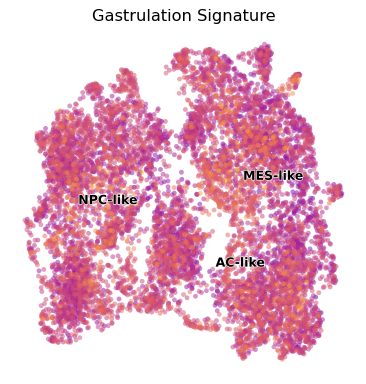

In [5]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'GSE162534', cmap = 'plasma', alpha = .5, size = 60,
           colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 60, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Gastrulation Signature', size = 13)
fig.savefig(os.path.join(pth_fig, 'Gast_signature.pdf'), bbox_inches = 'tight')

<cell>:2: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.


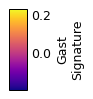

In [6]:
fig = plt.figure(figsize = (.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax); cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Gast\nSignature'); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'Gast_colorbar.pdf'), bbox_inches = 'tight')

### Somitogenesis signature (raw per-cell scores)

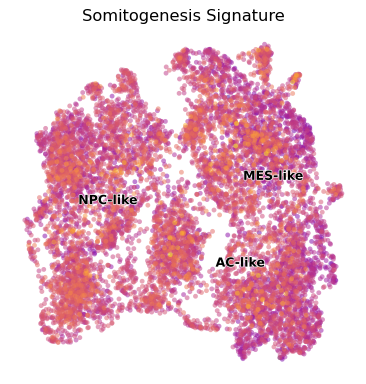

In [7]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'GSE229103', cmap = 'plasma', alpha = .5, size = 60,
           colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 60, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Somitogenesis Signature', size = 13)
fig.savefig(os.path.join(pth_fig, 'pSom_signature.pdf'), bbox_inches = 'tight')

<cell>:2: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.


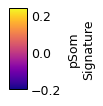

In [8]:
fig = plt.figure(figsize = (.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax); cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('pSom\nSignature'); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'pSom_colorbar.pdf'), bbox_inches = 'tight')

### Neural crest signature (raw per-cell scores)

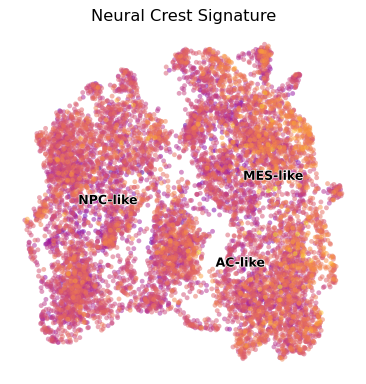

In [9]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'rRNAModifications', cmap = 'plasma', alpha = .5, size = 60,
           colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 60, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Neural Crest Signature', size = 13)
fig.savefig(os.path.join(pth_fig, 'Crest_signature.pdf'), bbox_inches = 'tight')

<cell>:2: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.


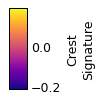

In [10]:
fig = plt.figure(figsize = (.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax); cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Crest\nSignature'); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'Crest_colorbar.pdf'), bbox_inches = 'tight')

### Save signatures data

In [11]:
adata.write(os.path.join(pth_in, 'signatures.h5ad'))
print('wrote signatures.h5ad', adata.shape)

wrote signatures.h5ad (9616, 26409)
